# Una superficie de bordo y espaciamiento: dos palancas a la vez en tres predictores

**Pregunta:** ¿Qué forma tiene la superficie de bordo y espaciamiento de cada predictor?

**Nivel 2: El método en la práctica** · Requiere: 06-design-response/01-moving-one-lever-at-a-time · Tiempo de lectura: unos 35 minutos

## Objetivos

Mover una palanca a la vez esconde cómo interactúan dos de ellas. El grupo Diseño de la aplicación web dibuja una superficie de respuesta sobre el bordo y el espaciamiento, con cada modelo recalculado sobre el diseño que cambia el lector. Este notebook construye esa superficie para un tiro de Akdaglar con el motor, y luego pregunta si su forma pertenece al predictor o al tiro.

Al terminar habrá:

- construido una grilla de 7 por 7 diseños a partir de un tiro con dos llamadas a `apply_variant` por punto, y reconstruido el volumen de roca de cada diseño;
- predicho la grilla con la ecuación clásica, la regresión publicada y gradient boosting, un predictor por celda, y dibujado las tres superficies en una misma escala de color;
- ajustado la pendiente log-log de cada superficie contra el volumen de roca y los exponentes del bordo y del espaciamiento, y comparado con los valores clásicos;
- repetido el barrido en los 22 tiros de la campaña y visto qué pendientes son propiedad del predictor.

## Preparación

Instale los paquetes con los pines exactos de `notebooks/requirements.txt`. El motor es `blastfrag`, publicado en PyPI; los otros paquetes son su base numérica y la biblioteca de gráficos.

```bash
pip install blastfrag==0.4.0 numpy==2.5.4 matplotlib==3.11.2
```

La celda de preparación importa los paquetes y las herramientas de variantes del producto (`apply_variant`, `is_degenerate`, el registro de casos y el registro `Variant`), imprime las versiones, carga los 22 tiros de Akdaglar y define `Table`. `display` muestra una tabla en medio de una celda que también dibuja o imprime.

In [1]:
# Importaciones, versiones de los paquetes y el cargador del corpus
from importlib.metadata import version
from pathlib import Path
import sys

sys.path.insert(0, str(Path("../../../data-pipeline")))
from pipeline.cases.fragmenta_cases import Variant
from pipeline.model.blasts import apply_variant, blasts_for_case, is_degenerate
from pipeline.registry import get_case
from IPython.display import display

import blastfrag as bf
import matplotlib.pyplot as plt
import numpy as np

for name in ("blastfrag", "numpy", "matplotlib"):
    print(f"{name}=={version(name)}")

train = bf.load_training_corpus()
print(len(train), "tiros de", len({b.site for b in train}), "campañas")

class Table:
    """Filas bajo un encabezado, mostradas como tabla Markdown"""

    def __init__(self, header, rows):
        self.header = list(header)
        self.rows = [[str(cell) for cell in row] for row in rows]

    def _repr_markdown_(self):
        lines = ["| " + " | ".join(self.header) + " |", "|" + "---|" * len(self.header)]
        lines += ["| " + " | ".join(row) + " |" for row in self.rows]
        return "\n".join(lines)

    __repr__ = _repr_markdown_

case = get_case("real-akdaglar")
blasts = blasts_for_case(case)

blastfrag==0.4.0
numpy==2.5.4
matplotlib==3.11.2
97 tiros de 10 campañas


## Datos

| Fuente | Titular y URL | Clase de licencia | Archivo que lee el notebook |
|---|---|---|---|
| Los tiros de Akdaglar y el resto del corpus, para entrenar gradient boosting | Hudaverdi, Kulatilake y Kuzu 2010, https://doi.org/10.1002/nag.957 | hechos numéricos reutilizados con cita; el artículo nunca se distribuye | el corpus dentro del paquete `blastfrag` |
| El mecanismo de variantes y la protección contra diseños degenerados | este repositorio (MIT) | la licencia propia del producto | `data-pipeline/pipeline/model/blasts.py`, importado por ruta |

Los factores del barrido, de 0,7 a 1,3 en siete pasos, son entradas de este notebook: un rango alrededor del diseño base que se mantiene dentro de la envolvente del corpus.

## Método

Un punto de la grilla es un tiro con dos multiplicadores aplicados: uno sobre la razón bordo-diámetro `B/D`, que escala todas las longitudes de la malla juntas porque el diámetro es fijo, y otro sobre la razón espaciamiento-bordo `S/B`, que estira solo el espaciamiento. `apply_variant` aplica un multiplicador, así que dos llamadas construyen un punto, e `is_degenerate` comprueba que el resultado siga siendo una voladura. `reconstruct_pattern` convierte luego las razones en metros y entrega el volumen de roca por perforación `V = B S H`.

Con un multiplicador `f_b` sobre la razón de bordo y `f_s` sobre la razón de espaciamiento, el volumen cambia en `f_b^3 f_s`: el multiplicador del bordo escala el bordo, el espaciamiento y la altura, y el del espaciamiento solo el espaciamiento. Para la ecuación clásica, `x50 = A (V/Q)^0.8 Q^(1/6) ...` (Kuznetsov 1973 como la imprimen Amoako, Jha y Zhong 2022, https://doi.org/10.3390/mining2020013), con factor de carga fijo `V/Q` es constante y el tamaño varía solo como `Q^(1/6)`, es decir como `V^(1/6)`. Su superficie es por tanto función del volumen solamente, con exponente 1/6 sobre el volumen, 1/2 sobre `f_b` y 1/6 sobre `f_s`.

La regresión es una ley de potencia de las siete razones (Hudaverdi, Kulatilake y Kuzu 2010, https://doi.org/10.1002/nag.957): suave, con un exponente ajustado por razón y sin motivo para depender solo del volumen. Gradient boosting (Sui et al. 2025, https://doi.org/10.3390/app15031254) solo puede devolver los valores que guardan sus hojas.

### Paso 1: el tiro base, los predictores y los multiplicadores

La celda toma el tiro `Ad1` de Akdaglar como diseño base, construye los tres predictores (gradient boosting se entrena sin Akdaglar) y fija siete multiplicadores de 0,7 a 1,3.

In [2]:
# Un tiro base, los tres predictores y una grilla de 7 por 7 multiplicadores
base = next(blast for blast in blasts if blast.blast_id == "Ad1")
arms = {
    "kuznetsov": bf.Kuznetsov(dict(bf.SITE_ROCK_FACTOR)),
    "published-regression": bf.PublishedRegression(),
    "xgboost": bf.default_arms()["xgboost"]().fit([blast for blast in train if blast.site != case.site]),
}
factors = np.linspace(0.7, 1.3, 7)
print("diseño base:", base.blast_id, "|", base.site, "| B/D", base.B_over_D, "| S/B", base.S_over_B, "| H/B",
    base.H_over_B)
print("multiplicadores:", [round(float(f), 2) for f in factors])

diseño base: Ad1 | Akdaglar | B/D 28.09 | S/B 1.2 | H/B 4.4
multiplicadores: [0.7, 0.8, 0.9, 1.0, 1.1, 1.2, 1.3]


### Paso 2: los 49 diseños y su volumen de roca

Para cada par de multiplicadores la celda construye el diseño con dos llamadas a `apply_variant` y reconstruye su volumen. Cuenta los diseños degenerados, que habría que dejar en blanco, e imprime el rango de volúmenes que cubre la grilla.

In [3]:
# Construir los 49 diseños con dos llamadas a apply_variant cada uno y reconstruir el volumen de roca de cada uno
designs = {}
volume = np.full((7, 7), np.nan)
for i, burden_factor in enumerate(factors):
    for j, spacing_factor in enumerate(factors):
        wider_burden = apply_variant(base, Variant("grid-b", "", "", "B_over_D", float(burden_factor)))
        designs[i, j] = apply_variant(wider_burden, Variant("grid-s", "", "", "S_over_B", float(spacing_factor)))
        volume[i, j] = bf.reconstruct_pattern(designs[i, j]).rock_volume_m3
degenerate = sum(is_degenerate(design) is not None for design in designs.values())
surface = {}
print("diseños:", len(designs), "| degenerados:", degenerate)
print(f"volumen de roca por perforación, base = {volume[3, 3]:.1f} m3")
print(f"rango {volume.min():.1f} - {volume.max():.1f} m3")

diseños: 49 | degenerados: 0
volumen de roca por perforación, base = 82.5 m3
rango 19.8 - 235.6 m3


**Qué muestra la salida.** Ningún diseño de la grilla es degenerado, y el volumen por perforación va de 19,8 m3 a 235,6 m3 en torno al valor base de 82,5 m3: un factor de doce entre las esquinas, porque el volumen se mueve con el cubo de un multiplicador. Un barrido de 0,7 a 1,3 no es entonces una perturbación pequeña de la malla; es el rango entre una malla cerrada y una muy abierta. **Qué no muestra:** si los tiros de las esquinas podrían tronarse. El producto solo garantiza que siguen siendo voladuras. Las tres celdas siguientes predicen toda la grilla, un predictor cada una.

### Paso 3: predecir la grilla, un predictor por celda

Primero **la ecuación clásica**. La celda predice cada diseño, omitiendo los degenerados, e imprime el rango de tamaños y cuántos valores distintos producen los 49 puntos.

In [4]:
# Predecir la grilla con kuznetsov
grid = np.full((7, 7), np.nan)
for (i, j), design in designs.items():
    if is_degenerate(design) is None:
        grid[i, j] = arms["kuznetsov"].predict_one(design).x50_m
surface["kuznetsov"] = grid
distinct = len(np.unique(np.round(grid, 9)))
print("kuznetsov             ", f"mín {np.nanmin(grid):.4f} m | máx {np.nanmax(grid):.4f} m",
    f"| valores distintos: {distinct}")

kuznetsov              mín 0.1705 m | máx 0.2576 m | valores distintos: 49


**La regresión publicada** a continuación, con el mismo bucle. Es una ley de potencia, así que también debería devolver 49 valores distintos, en un rango propio.

In [5]:
# Predecir la grilla con published-regression
grid = np.full((7, 7), np.nan)
for (i, j), design in designs.items():
    if is_degenerate(design) is None:
        grid[i, j] = arms["published-regression"].predict_one(design).x50_m
surface["published-regression"] = grid
distinct = len(np.unique(np.round(grid, 9)))
print("published-regression  ", f"mín {np.nanmin(grid):.4f} m | máx {np.nanmax(grid):.4f} m",
    f"| valores distintos: {distinct}")

published-regression   mín 0.1341 m | máx 0.2450 m | valores distintos: 49


**Gradient boosting** al final. Un conjunto de árboles devuelve solo lo que guardan sus hojas, así que el número a observar es la cantidad de valores distintos.

In [6]:
# Predecir la grilla con xgboost
grid = np.full((7, 7), np.nan)
for (i, j), design in designs.items():
    if is_degenerate(design) is None:
        grid[i, j] = arms["xgboost"].predict_one(design).x50_m
surface["xgboost"] = grid
distinct = len(np.unique(np.round(grid, 9)))
print("xgboost               ", f"mín {np.nanmin(grid):.4f} m | máx {np.nanmax(grid):.4f} m",
    f"| valores distintos: {distinct}")

xgboost                mín 0.2185 m | máx 0.2870 m | valores distintos: 17


### Paso 4: las tres superficies

La figura dibuja las tres grillas lado a lado en una escala de color común, para que se lean tanto las diferencias de nivel como las de forma. Las líneas blancas unen los diseños con el mismo volumen de roca. Un predictor que dependa solo del volumen tiene color constante a lo largo de ellas.

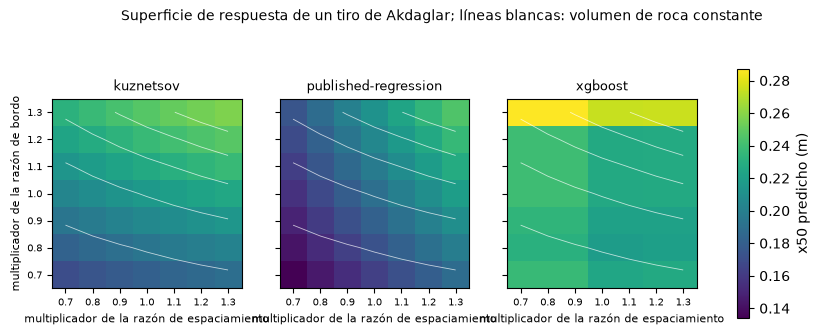

In [7]:
# Las tres superficies en una escala de color; la celda central es el diseño base
low = min(np.nanmin(grid) for grid in surface.values())
high = max(np.nanmax(grid) for grid in surface.values())
fig, axes = plt.subplots(1, 3, figsize=(10.4, 3.8), sharey=True)
for ax, (name, grid) in zip(axes, surface.items()):
    image = ax.imshow(grid, origin="lower", vmin=low, vmax=high, cmap="viridis")
    ax.contour(volume, levels=5, colors="white", linewidths=0.6, alpha=0.7)
    ax.set_xticks(range(7), [f"{f:.1f}" for f in factors], fontsize=7)
    ax.set_yticks(range(7), [f"{f:.1f}" for f in factors], fontsize=7)
    ax.set_title(name, fontsize=9)
    ax.set_xlabel("multiplicador de la razón de espaciamiento", fontsize=8)
axes[0].set_ylabel("multiplicador de la razón de bordo", fontsize=8)
fig.colorbar(image, ax=axes, shrink=0.85, label="x50 predicho (m)")
fig.suptitle("Superficie de respuesta de un tiro de Akdaglar; líneas blancas: volumen de roca constante", fontsize=10)
plt.show()

**Qué muestra la figura.** La superficie clásica (izquierda) tiene color constante a lo largo de las líneas blancas: es función del volumen de roca, y crece con ambos multiplicadores, de 0,1705 m a 0,2576 m. La regresión (centro) también es suave, de 0,1341 m a 0,2450 m, pero su color cruza las líneas blancas: responde más al espaciamiento que al bordo, así que diseños de igual volumen no son de igual tamaño. La superficie de boosting (derecha) es una escalera de bloques planos con 17 valores distintos, entre 0,2185 m y 0,2870 m, con su bloque más grueso en el bordo más ancho. **Qué no muestra:** cuál superficie es la correcta, pues ningún dato de campo registra la respuesta de una mina a la malla; y muestra un solo tiro. **Qué se sigue:** las celdas siguientes miden la forma en lugar de mirarla.

### Paso 5: la forma como números

Dos ajustes por superficie sobre los 49 puntos. Primero `ln x50 = a + s ln V`, la pendiente log-log `s` contra el volumen de roca y su r2: una potencia pura del volumen es una recta con r2 igual a 1. Segundo `ln x50 = a + b ln f_b + c ln f_s`, los exponentes sobre los dos multiplicadores por separado, que la ecuación clásica fija en 1/2 y 1/6. La tabla da ambos, y la figura dibuja cada diseño en el plano log-log con su recta ajustada.

In [8]:
# Ajustar ln x50 = a + b ln(multiplicador de bordo) + c ln(multiplicador de espaciamiento) en la grilla, y la
# pendiente contra ln V
log_b = np.log(np.repeat(factors, 7))
log_s = np.log(np.tile(factors, 7))
log_v = np.log(volume.ravel())
slopes = {}
rows = []
for name, grid in surface.items():
    log_x = np.log(grid.ravel())
    slope, intercept = np.polyfit(log_v, log_x, 1)
    elasticity = np.linalg.lstsq(np.column_stack([np.ones(49), log_b, log_s]), log_x, rcond=None)[0]
    r2 = 1 - np.sum((log_x - (slope * log_v + intercept)) ** 2) / np.sum((log_x - log_x.mean()) ** 2)
    slopes[name] = (slope, intercept, r2)
    rows.append((name, f"{slope:.4f}", f"{r2:.3f}", f"{elasticity[1]:.3f}", f"{elasticity[2]:.3f}"))
display(Table(["predictor", "pendiente de ln x50 sobre ln V", "r2 de esa recta", "exponente del bordo",
    "exponente del espaciamiento"], rows))
print("la ecuación clásica en papel:", f"1/6 = {1 / 6:.4f}", "| bordo", f"{3 / 6:.3f}", "| espaciamiento",
    f"{1 / 6:.3f}")

| predictor | pendiente de ln x50 sobre ln V | r2 de esa recta | exponente del bordo | exponente del espaciamiento |
|---|---|---|---|---|
| kuznetsov | 0.1667 | 1.000 | 0.500 | 0.167 |
| published-regression | 0.1828 | 0.694 | 0.427 | 0.547 |
| xgboost | 0.0545 | 0.225 | 0.217 | -0.105 |

la ecuación clásica en papel: 1/6 = 0.1667 | bordo 0.500 | espaciamiento 0.167


La celda siguiente pone los 49 diseños de cada predictor en el plano log-log contra el volumen de roca, con la recta ajustada detrás. Una ley de potencia pura es una recta que pasa por todos los puntos, así que lo que importa es cuán pegado a su recta queda cada color.

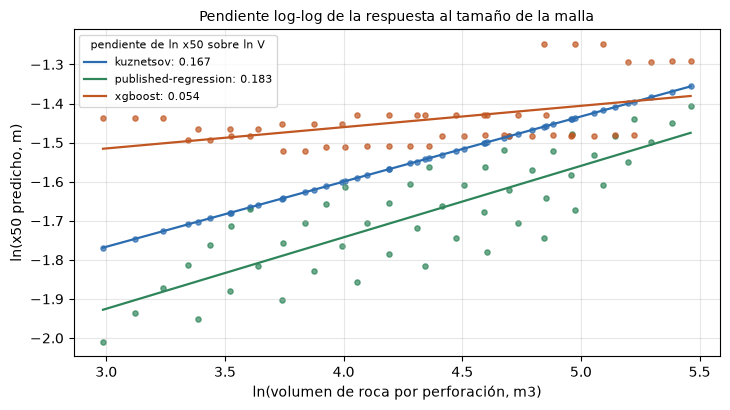

In [9]:
# ln x50 contra ln del volumen de roca para los 49 diseños, con la recta ajustada de cada predictor
fig, ax = plt.subplots(figsize=(7.4, 4.2))
colors = {"kuznetsov": "#2b6cb0", "published-regression": "#2f855a", "xgboost": "#c05621"}
log_v = np.log(volume.ravel())
for name, grid in surface.items():
    slope, intercept, r2 = slopes[name]
    ax.scatter(log_v, np.log(grid.ravel()), s=14, color=colors[name], alpha=0.7)
    ax.plot(np.sort(log_v), slope * np.sort(log_v) + intercept, color=colors[name], lw=1.6,
        label=f"{name}: {slope:.3f}")
ax.set_xlabel("ln(volumen de roca por perforación, m3)")
ax.set_ylabel("ln(x50 predicho, m)")
ax.set_title("Pendiente log-log de la respuesta al tamaño de la malla", fontsize=10)
ax.legend(fontsize=8, title="pendiente de ln x50 sobre ln V", title_fontsize=8)
ax.grid(alpha=0.3)
fig.tight_layout()
plt.show()

**Qué muestra la figura.** Los puntos clásicos están exactamente sobre una recta de pendiente 0,1667, que es 1/6, con r2 igual a 1,000, y sus exponentes son 0,500 en el bordo y 0,167 en el espaciamiento, como dice la ecuación. Los puntos de la regresión se dispersan en torno a una recta más empinada (pendiente 0,1828) con un r2 de solo 0,694: no es función del volumen solamente, y sus exponentes son 0,427 en el bordo y 0,547 en el espaciamiento, así que hace al espaciamiento tres veces más influyente que la ecuación clásica y al bordo algo menos. Los puntos de boosting forman una nube plana (pendiente 0,0545, r2 0,225) con exponente negativo sobre el espaciamiento, -0,105. **Qué no muestra:** que una recta sea el modelo correcto de una escalera; el ajuste solo resume su inclinación. **Qué se sigue:** la regresión y la ecuación clásica discrepan sobre cómo la malla cambia bordo por espaciamiento.

### Paso 6: ¿la forma es del predictor o del tiro?

Un tiro podría no ser representativo. La celda repite todo el barrido (los 49 diseños, los volúmenes, las tres predicciones y el ajuste de pendiente) en cada uno de los 22 tiros de la campaña, y guarda la pendiente de cada predictor para cada tiro.

In [10]:
# Repetir el barrido en los 22 tiros de Akdaglar y guardar la pendiente log-log de cada predictor, cada vez
all_slopes = {name: [] for name in arms}
for blast in blasts:
    designs_of = {}
    for i, burden_factor in enumerate(factors):
        for j, spacing_factor in enumerate(factors):
            step = apply_variant(blast, Variant("grid-b", "", "", "B_over_D", float(burden_factor)))
            designs_of[i, j] = apply_variant(step, Variant("grid-s", "", "", "S_over_B", float(spacing_factor)))
    log_v = np.log([bf.reconstruct_pattern(d).rock_volume_m3 for d in designs_of.values()])
    for name, arm in arms.items():
        log_x = np.log([arm.predict_one(d).x50_m for d in designs_of.values()])
        all_slopes[name].append(np.polyfit(log_v, log_x, 1)[0])
rows = [(n, f"{min(v):+.3f}", f"{np.median(v):+.3f}", f"{max(v):+.3f}", sum(s > 0 for s in v)) for n,
    v in all_slopes.items()]
Table(["predictor", "menor pendiente", "mediana", "mayor pendiente", "tiros con pendiente positiva (de 22)"], rows)

| predictor | menor pendiente | mediana | mayor pendiente | tiros con pendiente positiva (de 22) |
|---|---|---|---|---|
| kuznetsov | +0.167 | +0.167 | +0.167 | 22 |
| published-regression | +0.183 | +0.183 | +0.183 | 22 |
| xgboost | -0.105 | -0.030 | +0.062 | 4 |

La celda siguiente dibuja, para cada predictor, la pendiente de los 22 tiros como 22 puntos en una columna, con el 1/6 clásico como línea de trazos y el cero como una línea gris delgada. Una forma que pertenece al predictor da un único punto repetido; una forma que pertenece al tiro da una dispersión.

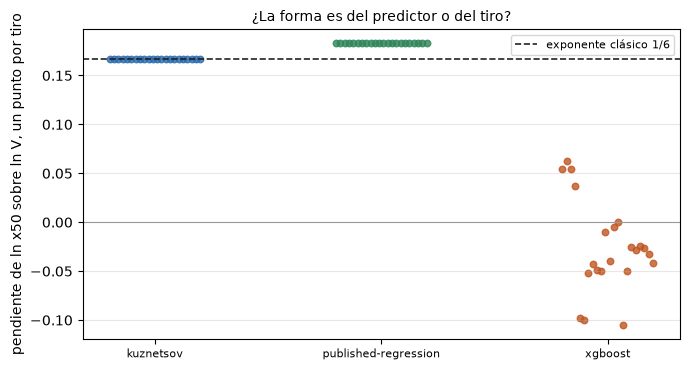

In [11]:
# La pendiente de cada uno de los 22 tiros por predictor; la línea de trazos es el 1/6 clásico
fig, ax = plt.subplots(figsize=(7, 3.8))
for k, (name, values) in enumerate(all_slopes.items()):
    ax.scatter(np.full(len(values), k) + np.linspace(-0.2, 0.2, len(values)), values, s=22, color=colors[name],
        alpha=0.8)
ax.axhline(1 / 6, color="#222", ls="--", lw=1.2, label="exponente clásico 1/6")
ax.axhline(0, color="#999", lw=0.8)
ax.set_xticks(range(len(all_slopes)), list(all_slopes), fontsize=8)
ax.set_ylabel("pendiente de ln x50 sobre ln V, un punto por tiro")
ax.set_title("¿La forma es del predictor o del tiro?", fontsize=10)
ax.legend(fontsize=8)
ax.grid(axis="y", alpha=0.3)
fig.tight_layout()
plt.show()

**Qué muestra la figura.** Para la ecuación clásica las 22 pendientes son un solo punto en +0,167, y para la regresión uno en +0,183: la misma en todos los tiros, que es lo que significa una forma funcional fija. Las pendientes de boosting se dispersan de -0,105 a +0,062 en torno a una mediana de -0,030, y solo 4 de las 22 son positivas: en la mayoría de los tiros la superficie aprendida cae cuando se abre la malla, contra ambas formas cerradas. **Qué no muestra:** que la pendiente aprendida sea errada; las filas de entrenamiento podrían no sostener una tendencia a esta escala. **Qué se sigue:** la forma de las superficies clásica y de regresión pertenece al predictor y es igual para todos los tiros, mientras que la forma de la superficie aprendida pertenece al tiro y a la posición de sus hojas, y no tiene un signo consistente.

## Resultados

**Respuesta:** la superficie clásica es una potencia suave del volumen de roca, la de la regresión es una potencia suave de las dos razones con otro equilibrio, y la superficie aprendida es una escalera sin dirección consistente. La pendiente clásica de ln x50 sobre ln V es 0,1667, igual a 1/6, con r2 de 1,000 y exponentes de 0,500 y 0,167 en el bordo y el espaciamiento. La pendiente de la regresión es 0,1828 con r2 0,694, porque sus exponentes (0,427 en el bordo, 0,547 en el espaciamiento) no se combinan en una función del volumen. Gradient boosting devuelve 17 valores distintos en los 49 diseños del tiro base, con una pendiente de 0,0545 y r2 de 0,225, y en los 22 tiros su pendiente va de -0,105 a +0,062, positiva en solo 4.

Las dos formas cerradas son entonces propiedades reproducibles del predictor, iguales en los 22 tiros (+0,167 y +0,183), mientras que la forma aprendida no lo es: no se resume con un exponente, y el producto muestra la superficie aprendida como superficie, no como tendencia.

**Qué no muestra esto.** Las tres superficies son respuestas de modelos sobre tiros de una campaña, en un barrido que cubre un factor de doce en volumen de roca. Ningún conjunto de datos registra qué hace cambiar la malla en una mina dada, así que ninguna superficie puede llamarse la correcta. La superficie responde qué dice cada modelo, no cómo quedará la pila de material.

## Resumen

- Dos llamadas a `apply_variant` construyen un punto de la grilla, `is_degenerate` lo protege y `reconstruct_pattern` da su volumen de roca; 49 diseños cubren un factor de doce en volumen.
- La superficie clásica es una potencia 1/6 del volumen (r2 1,000); la regresión es suave pero no función del volumen (r2 0,694); boosting es una escalera de 17 valores.
- Las pendientes clásica y de regresión son iguales en los 22 tiros; la de boosting cambia de signo de un tiro a otro.
- Siguiente: el notebook 03 muestra cómo se sirven en vivo los predictores aprendidos desde un documento portable (nivel 4).

## Referencias

- Hudaverdi, Kulatilake y Kuzu 2010, https://doi.org/10.1002/nag.957 (el corpus y la regresión publicada)
- Amoako, Jha y Zhong 2022, https://doi.org/10.3390/mining2020013 (regresión de vectores de soporte, núcleo rbf; la ecuación clásica)
- Sui, Zhou, Zhao, Yang y Zou 2025, https://doi.org/10.3390/app15031254 (vectores de soporte polinómico, bosque, boosting, apilamiento)
- `blastfrag` 0.4.0, el motor, en PyPI: https://pypi.org/project/blastfrag/